In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import accuracy_score

In [2]:
dataset = pd.read_csv('Social_Network_Ads.csv')
X = dataset.iloc[:, :-1].values
y = dataset.iloc[:, -1].values

In [3]:
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 0)

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(random_state = 0))
])

parameters = [
    {'svm__C': [0.25, 0.5, 0.75, 1.0], 'svm__kernel': ['linear']},
    {'svm__C': [0.25, 0.5, 0.75, 1.0], 'svm__kernel': ['rbf'], 'svm__gamma': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]}
]

In [5]:
grid_search = GridSearchCV(estimator = svm_pipeline,
                           param_grid= parameters,
                           scoring = 'accuracy',
                           cv = 10,
                           n_jobs = 1)

In [6]:
grid_search.fit(X_train, y_train)

GridSearchCV(cv=10,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('svm', SVC(random_state=0))]),
             n_jobs=1,
             param_grid=[{'svm__C': [0.25, 0.5, 0.75, 1.0],
                          'svm__kernel': ['linear']},
                         {'svm__C': [0.25, 0.5, 0.75, 1.0],
                          'svm__gamma': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8,
                                         0.9],
                          'svm__kernel': ['rbf']}],
             scoring='accuracy')

In [7]:
print('Best accuracy: {:.2f}%'.format(grid_search.best_score_*100))
print('Best parameters:', grid_search.best_params_)

Best accuracy: 91.00%
Best parameters: {'svm__C': 1.0, 'svm__gamma': 0.7, 'svm__kernel': 'rbf'}


In [8]:
y_pred = grid_search.predict(X_test)
print("Final Test Accuracy: {:.2f} %".format(accuracy_score(y_test, y_pred) * 100))

Final Test Accuracy: 93.00 %


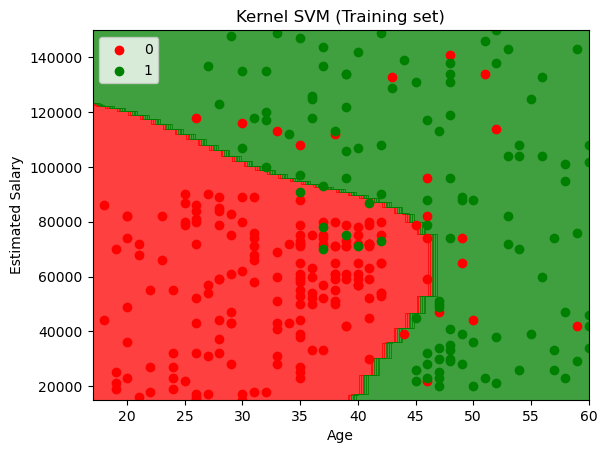

In [9]:
from matplotlib.colors import ListedColormap
X_set, y_set = X_train, y_train
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1, stop = X_set[:, 0].max() + 1, step = 1),
                     np.arange(start = X_set[:, 1].min() - 1, stop = X_set[:, 1].max() + 1, step = 100))
plt.contourf(X1, X2, grid_search.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('red', 'green')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                color = ListedColormap(('red', 'green'))(i), label = j)
plt.title('Kernel SVM (Training set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()

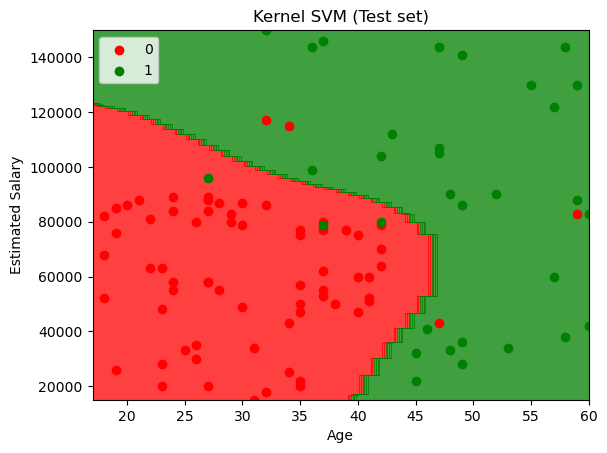

In [10]:
from matplotlib.colors import ListedColormap
X_set, y_set = X_test, y_test
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1, stop = X_set[:, 0].max() + 1, step = 1),
                     np.arange(start = X_set[:, 1].min() - 1, stop = X_set[:, 1].max() + 1, step = 100))
plt.contourf(X1, X2, grid_search.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('red', 'green')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                color = ListedColormap(('red', 'green'))(i), label = j)
plt.title('Kernel SVM (Test set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()